# Project 2: MovieLens Bipartite Network Analysis
**Anthony Roman**  
**DATA 620: Web Analytics**

## Introduction

This project examines a bipartite network using the MovieLens 100K dataset. The network contains two distinct groups: users and movies. An edge connects a user to a movie that the user rated. No edges connect users directly to other users or movies directly to other movies.

The analysis addresses the following question:

**How does reducing a user–movie network reveal patterns in user participation and movie popularity?**

The original network will be summarized and reduced using a k-core approach, which repeatedly removes nodes with fewer than a specified number of connections. The analysis will compare the original and reduced networks and examine what the results reveal about users and movies.

Movie popularity will refer to the number of ratings received, while average ratings will be examined separately as a measure of user evaluation.

In [3]:
from pathlib import Path
from urllib.request import urlretrieve
from zipfile import ZipFile

import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt

from IPython.display import display

pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 70)

plt.rcParams.update({
    "figure.figsize": (10, 6),
    "font.size": 11
})

## Data Source

The MovieLens 100K dataset is provided by GroupLens Research at the University of Minnesota. It includes 100,000 ratings from 943 users on 1,682 movies. Ratings range from 1 to 5.

The files used in this project are:

- `u.data`: User IDs, movie IDs, ratings, and timestamps.
- `u.item`: Movie titles, release information, and genre indicators.

Source: https://grouplens.org/datasets/movielens/100k/

In [ ]:
import pandas as pd
from io import BytesIO
from urllib.request import urlopen

base_url = (
    "https://raw.githubusercontent.com/"
    "jsnowacki/SPARK/master/data/ml-100k/"
)

with urlopen(base_url + "u.data", timeout=60) as response:
    ratings = pd.read_csv(
        BytesIO(response.read()),
        sep="\t",
        names=["user_id", "movie_id", "rating", "timestamp"]
    )

assert len(ratings) == 100_000, "Unexpected number of ratings."
assert ratings["user_id"].nunique() == 943, "Unexpected user count."
assert ratings["movie_id"].nunique() == 1_682, "Unexpected movie count."

print(f"Ratings: {len(ratings):,}")
print(f"Unique users: {ratings['user_id'].nunique():,}")
print(f"Unique movies: {ratings['movie_id'].nunique():,}")

display(ratings.head())

Ratings: 100,000
Unique users: 943
Unique movies: 1,682


,user_id,movie_id,rating,timestamp
0,196,242,3,881250949
1,186,302,3,891717742
2,22,377,1,878887116
3,244,51,2,880606923
4,166,346,1,886397596


## Data Preparation

Movie information is loaded to attach titles and genres to the movie nodes. Both files are read directly from an online copy of the MovieLens 100K dataset.

Before constructing the network, the data are checked for missing identifiers, duplicate user–movie pairs, invalid ratings, and movie IDs without matching metadata. Each user–movie pair should represent one edge.

In [6]:
genre_columns = [
    "unknown", "Action", "Adventure", "Animation", "Children's",
    "Comedy", "Crime", "Documentary", "Drama", "Fantasy",
    "Film-Noir", "Horror", "Musical", "Mystery", "Romance",
    "Sci-Fi", "Thriller", "War", "Western"
]

movie_columns = [
    "movie_id", "title", "release_date",
    "video_release_date", "imdb_url"
] + genre_columns

with urlopen(base_url + "u.item", timeout=60) as response:
    movies = pd.read_csv(
        BytesIO(response.read()),
        sep="|",
        encoding="latin-1",
        names=movie_columns
    )

movies["genres"] = movies[genre_columns].apply(
    lambda row: ", ".join(
        genre for genre in genre_columns if row[genre] == 1
    ),
    axis=1
)

print(f"Movies loaded: {len(movies):,}")

display(movies[["movie_id", "title", "genres"]].head())

Movies loaded: 1,682


,movie_id,title,genres
0,1,Toy Story (1995),"Animation, Children's, Comedy"
1,2,GoldenEye (1995),"Action, Adventure, Thriller"
2,3,Four Rooms (1995),Thriller
3,4,Get Shorty (1995),"Action, Comedy, Drama"
4,5,Copycat (1995),"Crime, Drama, Thriller"


In [7]:
quality_checks = pd.Series({
    "Missing user IDs": ratings["user_id"].isna().sum(),
    "Missing movie IDs in ratings": ratings["movie_id"].isna().sum(),
    "Missing ratings": ratings["rating"].isna().sum(),
    "Duplicate user-movie pairs": ratings.duplicated(
        subset=["user_id", "movie_id"]
    ).sum(),
    "Invalid or missing rating values": (
        ~ratings["rating"].isin([1, 2, 3, 4, 5])
    ).sum(),
    "Missing movie IDs in metadata": movies["movie_id"].isna().sum(),
    "Duplicate movie IDs in metadata": movies["movie_id"].duplicated().sum(),
    "Missing movie titles": movies["title"].isna().sum(),
    "Rated movie IDs missing metadata": len(
        set(ratings["movie_id"]) - set(movies["movie_id"])
    )
}, name="Count")

display(quality_checks.to_frame())

assert quality_checks.eq(0).all(), (
    "Some data checks failed. Review the results before continuing."
)

print("All checks passed. The data are ready for network construction.")

,Count
Missing user IDs,0
Missing movie IDs in ratings,0
Missing ratings,0
Duplicate user-movie pairs,0
Invalid or missing rating values,0
Missing movie IDs in metadata,0
Duplicate movie IDs in metadata,0
Missing movie titles,0
Rated movie IDs missing metadata,0


All checks passed. The data are ready for network construction.


## Bipartite Network Construction

The network contains two groups of nodes: users and movies. An undirected edge connects each user to a movie they rated. The rating is stored as an edge attribute.

User nodes have a `user_` prefix, and movie nodes have a `movie_` prefix to prevent overlapping numeric IDs from being treated as the same node.

Degree measures the number of distinct connections. For users, it represents the number of movies rated. For movies, it represents the number of users who rated them. The later k-core reduction uses these connection counts rather than rating values.

In [8]:
B = nx.Graph()

B.add_nodes_from(
    (
        f"user_{user_id}",
        {"bipartite": 0, "node_type": "user", "user_id": int(user_id)}
    )
    for user_id in ratings["user_id"].unique()
)

B.add_nodes_from(
    (
        f"movie_{row.movie_id}",
        {
            "bipartite": 1,
            "node_type": "movie",
            "movie_id": int(row.movie_id),
            "title": row.title,
            "genres": row.genres
        }
    )
    for row in movies.itertuples(index=False)
)

B.add_edges_from(
    (
        f"user_{row.user_id}",
        f"movie_{row.movie_id}",
        {"rating": int(row.rating)}
    )
    for row in ratings.itertuples(index=False)
)

user_nodes = {
    node for node, data in B.nodes(data=True)
    if data["node_type"] == "user"
}

movie_nodes = {
    node for node, data in B.nodes(data=True)
    if data["node_type"] == "movie"
}

assert nx.is_bipartite(B), "The graph is not bipartite."
assert all(
    B.nodes[u]["node_type"] != B.nodes[v]["node_type"]
    for u, v in B.edges()
), "An edge connects nodes within the same group."

assert B.number_of_edges() == len(ratings), "Unexpected edge count."

print(f"User nodes: {len(user_nodes):,}")
print(f"Movie nodes: {len(movie_nodes):,}")
print(f"Total nodes: {B.number_of_nodes():,}")
print(f"Total edges: {B.number_of_edges():,}")
print("Bipartite structure verified.")

User nodes: 943
Movie nodes: 1,682
Total nodes: 2,625
Total edges: 100,000
Bipartite structure verified.


## Original Network Summary

Bipartite density measures the proportion of possible user–movie connections that are present. Only connections between the two groups are possible.

Connected components indicate whether all nodes belong to one connected network or whether separate groups exist. Average degree is calculated separately for users and movies because the two groups have different interpretations.

In [9]:
original_summary = pd.Series({
    "Users": len(user_nodes),
    "Movies": len(movie_nodes),
    "Total nodes": B.number_of_nodes(),
    "Edges": B.number_of_edges(),
    "Connected components": nx.number_connected_components(B),
    "Isolated nodes": nx.number_of_isolates(B),
    "Bipartite density": (
        B.number_of_edges() / (len(user_nodes) * len(movie_nodes))
    ),
    "Average movies rated per user": (
        B.number_of_edges() / len(user_nodes)
    ),
    "Average ratings received per movie": (
        B.number_of_edges() / len(movie_nodes)
    )
}, name="Original network")

display(original_summary.to_frame().round(4))

,Original network
Users,943.0000
Movies,1682.0000
Total nodes,2625.0000
Edges,100000.0000
Connected components,1.0000
Isolated nodes,0.0000
Bipartite density,0.0630
Average movies rated per user,106.0445
Average ratings received per movie,59.4530


### Interpretation of the Original Network

The original network contains 943 users, 1,682 movies, and 100,000 edges. It forms one connected component and has no isolated nodes, meaning every node can be reached from every other node through a sequence of user–movie connections.

The bipartite density is approximately 0.063, indicating that 6.3% of all possible user–movie connections are present. Users rated an average of 106.04 movies, while movies received an average of 59.45 ratings. These averages summarize participation but do not show how unevenly connections are distributed.

## Network Reduction Using K-Core Decomposition

A k-core is a subgraph in which every node has at least k neighbors within that subgraph. Nodes below the threshold are removed repeatedly until all remaining nodes satisfy the requirement.

For example, in a 20-core, every retained user has rated at least 20 retained movies, and every retained movie has been rated by at least 20 retained users.

This method preserves the bipartite structure and identifies a more densely connected subset of users and movies. It uses connection counts rather than rating values, so it does not identify whether users liked the movies.

Several thresholds are compared to examine the trade-off between network reduction and retention of the original data.

In [10]:
core_numbers = nx.core_number(B)
max_core = max(core_numbers.values())

print(f"Highest nonempty k-core: {max_core}")

thresholds = sorted(
    {k for k in [0, 10, 20, 30, 40, 50] if k <= max_core}
    | {max_core}
)

core_results = []

for k in thresholds:
    H = nx.k_core(B, k=k, core_number=core_numbers)

    n_users = sum(
        data["node_type"] == "user"
        for _, data in H.nodes(data=True)
    )
    n_movies = sum(
        data["node_type"] == "movie"
        for _, data in H.nodes(data=True)
    )
    n_edges = H.number_of_edges()

    core_results.append({
        "k": k,
        "users": n_users,
        "movies": n_movies,
        "nodes": H.number_of_nodes(),
        "edges": n_edges,
        "users_retained_pct": 100 * n_users / len(user_nodes),
        "movies_retained_pct": 100 * n_movies / len(movie_nodes),
        "edges_retained_pct": 100 * n_edges / B.number_of_edges(),
        "bipartite_density": (
            n_edges / (n_users * n_movies)
            if n_users and n_movies else 0
        ),
        "components": nx.number_connected_components(H)
    })

core_comparison = pd.DataFrame(core_results).set_index("k")

display(core_comparison.round(4))

Highest nonempty k-core: 83


,users,movies,nodes,edges,users_retained_pct,movies_retained_pct,edges_retained_pct,bipartite_density,components
k,,,,,,,,,
0,943,1682,2625,100000,100.0000,100.0000,100.000,0.0630,1
10,943,1152,2095,97953,100.0000,68.4899,97.953,0.0902,1
20,917,937,1854,94443,97.2428,55.7075,94.443,0.1099,1
30,720,795,1515,86295,76.3521,47.2652,86.295,0.1508,1
40,601,658,1259,77513,63.7328,39.1201,77.513,0.1960,1
50,513,560,1073,69222,54.4008,33.2937,69.222,0.2410,1
83,190,178,368,21122,20.1485,10.5826,21.122,0.6245,1


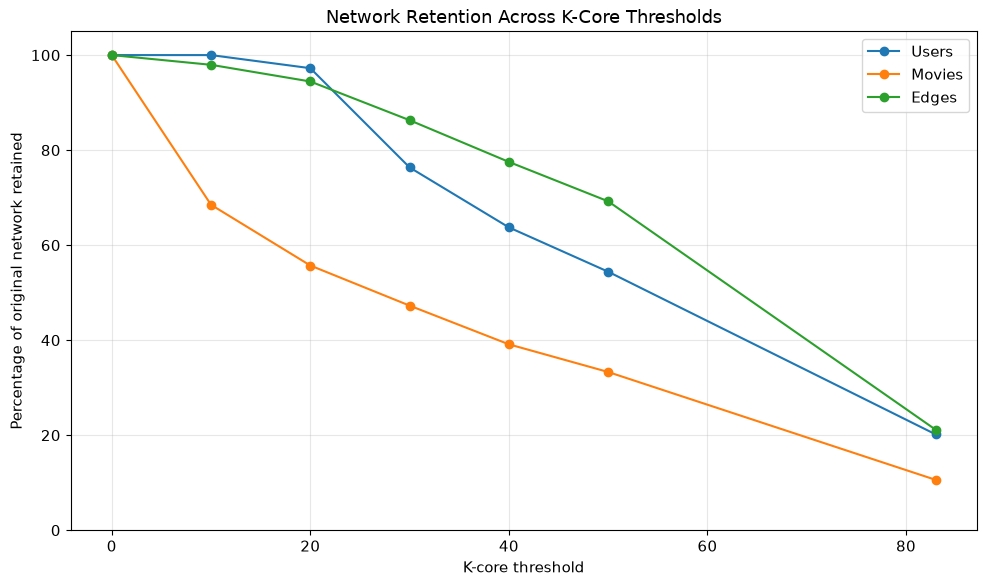

In [11]:
fig, ax = plt.subplots(figsize=(10, 6))

for column, label in [
    ("users_retained_pct", "Users"),
    ("movies_retained_pct", "Movies"),
    ("edges_retained_pct", "Edges")
]:
    ax.plot(
        core_comparison.index,
        core_comparison[column],
        marker="o",
        label=label
    )

ax.set_title("Network Retention Across K-Core Thresholds")
ax.set_xlabel("K-core threshold")
ax.set_ylabel("Percentage of original network retained")
ax.set_ylim(0, 105)
ax.grid(alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()

### Selecting the Reduction Threshold

The 50-core was selected as a practical balance between reducing network size and retaining rating relationships. It contains 513 users, 560 movies, and 69,222 edges. Compared with the original network, it retains approximately 54.4% of users, 33.3% of movies, and 69.2% of edges while removing approximately 59.1% of nodes.

The highest nonempty core, the 83-core, retains only 21.1% of the original edges. Although it identifies a tightly connected subset, it excludes substantially more of the dataset.

The selected network remains connected, and its bipartite density increases from approximately 0.063 to 0.241. Every retained user has rated at least 50 retained movies, and every retained movie has been rated by at least 50 retained users.

This reduction favors active users and frequently rated movies. The higher density is an expected consequence of the selection method, rather than independent evidence that the retained movies are better.

In [12]:
selected_k = 50

B_reduced = nx.k_core(
    B,
    k=selected_k,
    core_number=core_numbers
).copy()

reduced_users = user_nodes.intersection(B_reduced.nodes)
reduced_movies = movie_nodes.intersection(B_reduced.nodes)

assert nx.is_bipartite(B_reduced)
assert min(dict(B_reduced.degree()).values()) >= selected_k

print(f"Selected core: {selected_k}")
print(f"Users: {len(reduced_users):,}")
print(f"Movies: {len(reduced_movies):,}")
print(f"Edges: {B_reduced.number_of_edges():,}")
print(f"Minimum degree: {min(dict(B_reduced.degree()).values())}")

Selected core: 50
Users: 513
Movies: 560
Edges: 69,222
Minimum degree: 50


## Analysis of Users and Movies

The two node groups are analyzed separately because degree has a different meaning for each group.

For users, degree measures the number of distinct movies rated. For movies, degree measures the number of users who submitted a rating.

Original and reduced degrees are compared to show how connections change after filtering. Average movie ratings are also reported, but they measure evaluation rather than popularity. Averages in the reduced network reflect only retained users and may differ because of that selection.

In [13]:
retained_user_ids = {
    B.nodes[node]["user_id"] for node in reduced_users
}
retained_movie_ids = {
    B.nodes[node]["movie_id"] for node in reduced_movies
}

reduced_ratings = ratings.loc[
    ratings["user_id"].isin(retained_user_ids)
    & ratings["movie_id"].isin(retained_movie_ids)
].copy()

assert len(reduced_ratings) == B_reduced.number_of_edges()

user_analysis = (
    ratings.groupby("user_id")
    .agg(
        original_degree=("movie_id", "nunique"),
        original_mean_rating=("rating", "mean")
    )
)

user_reduced_stats = (
    reduced_ratings.groupby("user_id")
    .agg(
        reduced_degree=("movie_id", "nunique"),
        reduced_mean_rating=("rating", "mean")
    )
)

user_analysis = user_analysis.join(user_reduced_stats)
user_analysis["retained"] = user_analysis.index.isin(retained_user_ids)
user_analysis["reduced_degree"] = (
    user_analysis["reduced_degree"].fillna(0).astype(int)
)

movie_analysis = (
    ratings.groupby("movie_id")
    .agg(
        original_degree=("user_id", "nunique"),
        original_mean_rating=("rating", "mean")
    )
)

movie_reduced_stats = (
    reduced_ratings.groupby("movie_id")
    .agg(
        reduced_degree=("user_id", "nunique"),
        reduced_mean_rating=("rating", "mean")
    )
)

movie_analysis = (
    movie_analysis
    .join(movie_reduced_stats)
    .join(movies.set_index("movie_id")[["title", "genres"]])
)

movie_analysis["retained"] = movie_analysis.index.isin(retained_movie_ids)
movie_analysis["reduced_degree"] = (
    movie_analysis["reduced_degree"].fillna(0).astype(int)
)

print("Top 10 users by degree in the reduced network:")
display(
    user_analysis.loc[user_analysis["retained"]]
    .sort_values(
        ["reduced_degree", "user_id"],
        ascending=[False, True]
    )
    .head(10)
    .round(3)
)

print("Top 10 movies by degree in the reduced network:")
display(
    movie_analysis.loc[movie_analysis["retained"]]
    .sort_values(
        ["reduced_degree", "movie_id"],
        ascending=[False, True]
    )[
        [
            "title", "genres", "original_degree", "reduced_degree",
            "original_mean_rating", "reduced_mean_rating"
        ]
    ]
    .head(10)
    .round(3)
)

Top 10 users by degree in the reduced network:


,original_degree,original_mean_rating,reduced_degree,reduced_mean_rating,retained
user_id,,,,,
13,636,3.097,389,3.460,True
450,540,3.865,384,4.000,True
655,685,2.908,359,2.900,True
276,518,3.465,357,3.801,True
416,493,3.846,357,4.042,True
537,490,2.865,352,2.974,True
303,484,3.366,342,3.751,True
429,414,3.394,335,3.543,True
234,480,3.123,332,3.184,True


Top 10 movies by degree in the reduced network:


,title,genres,original_degree,reduced_degree,original_mean_rating,reduced_mean_rating
movie_id,,,,,,
50,Star Wars (1977),"Action, Adventure, Romance, Sci-Fi, War",583,431,4.358,4.383
181,Return of the Jedi (1983),"Action, Adventure, Romance, Sci-Fi, War",507,386,4.008,4.031
174,Raiders of the Lost Ark (1981),"Action, Adventure",420,376,4.252,4.269
100,Fargo (1996),"Crime, Drama, Thriller",508,371,4.156,4.154
56,Pulp Fiction (1994),"Crime, Drama",394,345,4.061,4.081
121,Independence Day (ID4) (1996),"Action, Sci-Fi, War",429,345,3.438,3.388
1,Toy Story (1995),"Animation, Children's, Comedy",452,344,3.878,3.898
98,"Silence of the Lambs, The (1991)","Drama, Thriller",390,344,4.290,4.314
172,"Empire Strikes Back, The (1980)","Action, Adventure, Drama, Romance, Sci-Fi, War",367,327,4.204,4.208


### Findings About Users

User 13 has the highest degree in the reduced network, with ratings for 389 retained movies, followed by user 450 with 384 and user 655 with 359.

The reduction can change users' relative positions. User 655 rated 685 movies in the original network, more than user 13's 636, but has fewer connections within the selected core. This shows that extensive overall participation does not necessarily produce the highest degree among retained movies.

The most active retained users also differ in their average ratings. For example, user 450 has a reduced mean rating of 4.000, compared with 2.900 for user 655. These differences could reflect rating habits, the movies selected, or both. Degree alone does not indicate how positively a user evaluates movies.

### Findings About Movies

Star Wars (1977) has the highest degree in the reduced network, receiving ratings from 431 of the 513 retained users, approximately 84.0%. Return of the Jedi (1983) follows with 386 ratings, and Raiders of the Lost Ark (1981) has 376.

Frequently rated movies are not necessarily equally well liked. Pulp Fiction (1994) and Independence Day (1996) each receive 345 ratings in the reduced network, but their average ratings are approximately 4.081 and 3.388, respectively.

The leading movies include action, adventure, science fiction, crime, drama, and other genres. However, the top ten alone cannot establish the genre composition of the entire reduced network. A separate comparison of all original and retained movies is needed.

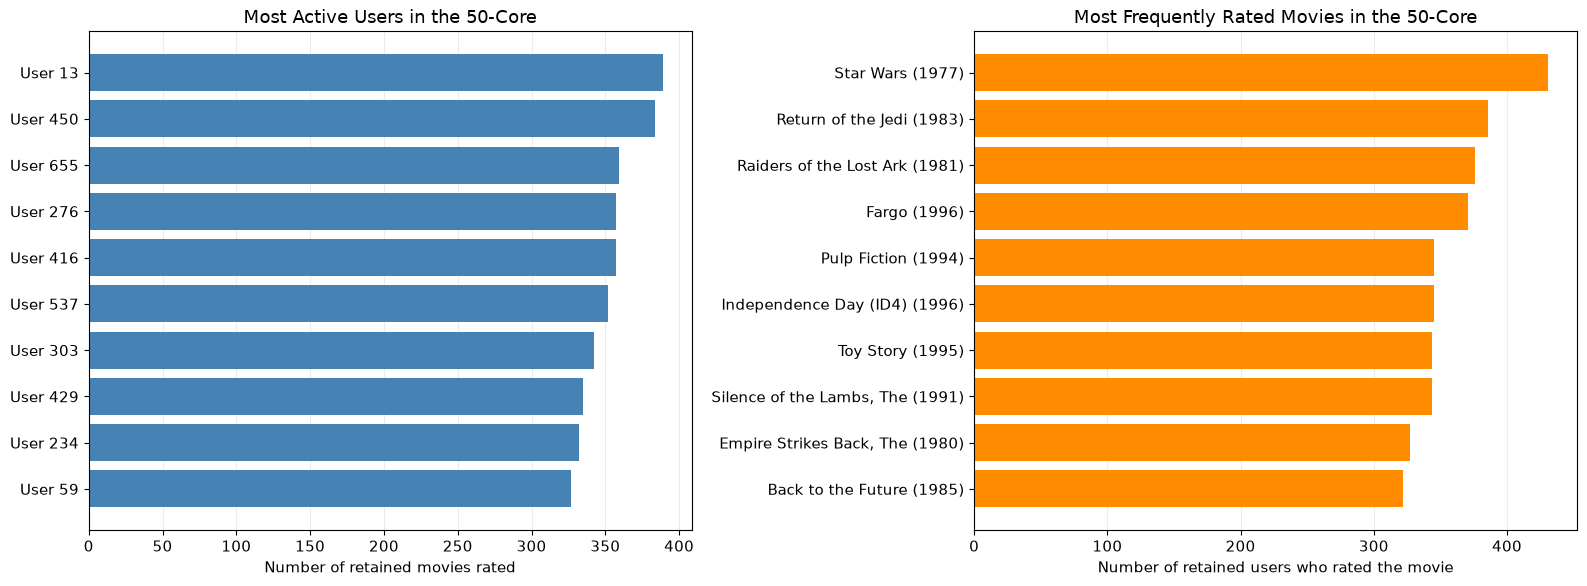

In [14]:
top_users = (
    user_analysis.loc[user_analysis["retained"]]
    .sort_values(
        ["reduced_degree", "user_id"],
        ascending=[False, True]
    )
    .head(10)
    .iloc[::-1]
)

top_movies = (
    movie_analysis.loc[movie_analysis["retained"]]
    .sort_values(
        ["reduced_degree", "movie_id"],
        ascending=[False, True]
    )
    .head(10)
    .iloc[::-1]
)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

axes[0].barh(
    [f"User {user_id}" for user_id in top_users.index],
    top_users["reduced_degree"],
    color="steelblue"
)
axes[0].set_title("Most Active Users in the 50-Core")
axes[0].set_xlabel("Number of retained movies rated")

axes[1].barh(
    top_movies["title"],
    top_movies["reduced_degree"],
    color="darkorange"
)
axes[1].set_title("Most Frequently Rated Movies in the 50-Core")
axes[1].set_xlabel("Number of retained users who rated the movie")

for ax in axes:
    ax.grid(axis="x", alpha=0.25)
    ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

## Genre Representation Before and After Reduction

Genre representation is compared using the percentage of movies belonging to each genre in the original and reduced networks. Percentages allow comparison despite the different numbers of movies.

A movie may belong to multiple genres, so the percentages do not sum to 100%. These measures describe the movie catalog represented in each network, rather than the proportion of ratings or users who prefer a genre.

In [15]:
original_movie_metadata = movies.loc[
    movies["movie_id"].isin(ratings["movie_id"])
]

retained_movie_metadata = movies.loc[
    movies["movie_id"].isin(retained_movie_ids)
]

genre_comparison = pd.DataFrame({
    "original_movies": original_movie_metadata[genre_columns].sum(),
    "retained_movies": retained_movie_metadata[genre_columns].sum()
})

genre_comparison["original_share_pct"] = (
    100 * genre_comparison["original_movies"]
    / len(original_movie_metadata)
)

genre_comparison["reduced_share_pct"] = (
    100 * genre_comparison["retained_movies"]
    / len(retained_movie_metadata)
)

genre_comparison["change_percentage_points"] = (
    genre_comparison["reduced_share_pct"]
    - genre_comparison["original_share_pct"]
)

genre_comparison = genre_comparison.sort_values(
    "reduced_share_pct",
    ascending=False
)

display(genre_comparison.round(2))

,original_movies,retained_movies,original_share_pct,reduced_share_pct,change_percentage_points
Drama,725,224,43.10,40.00,-3.10
Comedy,505,179,30.02,31.96,1.94
Action,251,127,14.92,22.68,7.76
Thriller,251,117,14.92,20.89,5.97
Romance,247,105,14.68,18.75,4.07
Adventure,135,75,8.03,13.39,5.37
Sci-Fi,101,61,6.00,10.89,4.89
War,71,46,4.22,8.21,3.99
Children's,122,42,7.25,7.50,0.25
Crime,109,42,6.48,7.50,1.02


### Genre Findings

Drama remains the most common genre in the reduced network, accounting for 224 of 560 movies, or 40.00%. However, its share decreases from 43.10% in the original network. Comedy remains second, increasing from 30.02% to 31.96%.

Action shows the largest increase in representation, rising from 14.92% to 22.68%, a gain of 7.76 percentage points. Thriller, adventure, and science fiction also increase their shares. These genres are more strongly represented among movies that meet the core's connectivity requirement.

Documentaries show a different pattern. Only 3 of the original 50 documentary movies remain, and their share decreases from 2.97% to 0.54%. This illustrates how a connectivity-based reduction can exclude less frequently rated categories.

These differences describe the composition of the retained catalog. They do not establish that users prefer one genre over another, because the reduction uses rating counts rather than rating scores, and movies can belong to multiple genres.

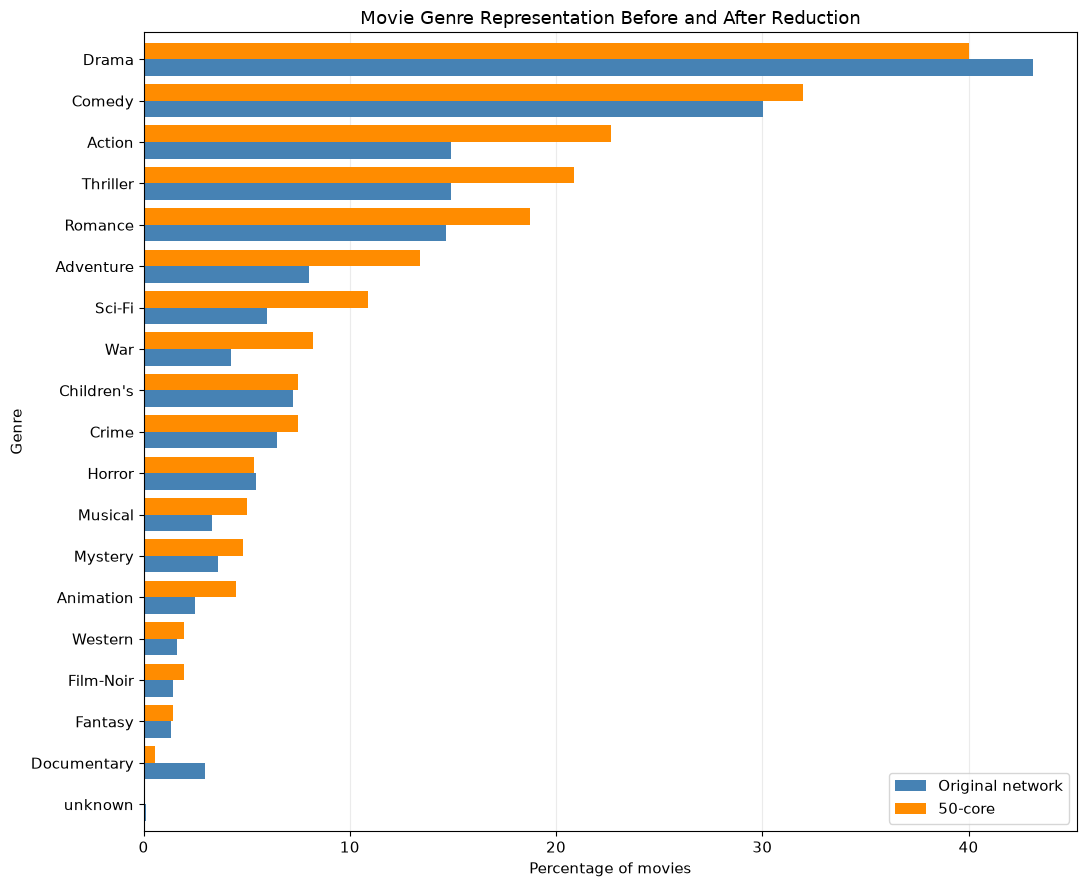

In [16]:
genre_plot = genre_comparison[
    ["original_share_pct", "reduced_share_pct"]
].iloc[::-1]

ax = genre_plot.plot.barh(
    figsize=(11, 9),
    color=["steelblue", "darkorange"],
    width=0.8
)

ax.set_title("Movie Genre Representation Before and After Reduction")
ax.set_xlabel("Percentage of movies")
ax.set_ylabel("Genre")
ax.legend(["Original network", "50-core"])
ax.grid(axis="x", alpha=0.25)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

## Visualizing the Bipartite Structure

The reduced network still contains 1,073 nodes and 69,222 edges, making a complete node-link diagram difficult to read.

For illustration, 12 users and 12 movies are sampled from the reduced network using a fixed random seed. All existing edges between these selected nodes are displayed. This visualization sample is separate from the 50-core reduction and is not used to calculate the reported findings.

Users and movies appear in separate columns. Connections occur only between the two groups. Nodes may appear isolated in this illustration because their neighbors were not sampled, even though the full reduced network has no isolated nodes.

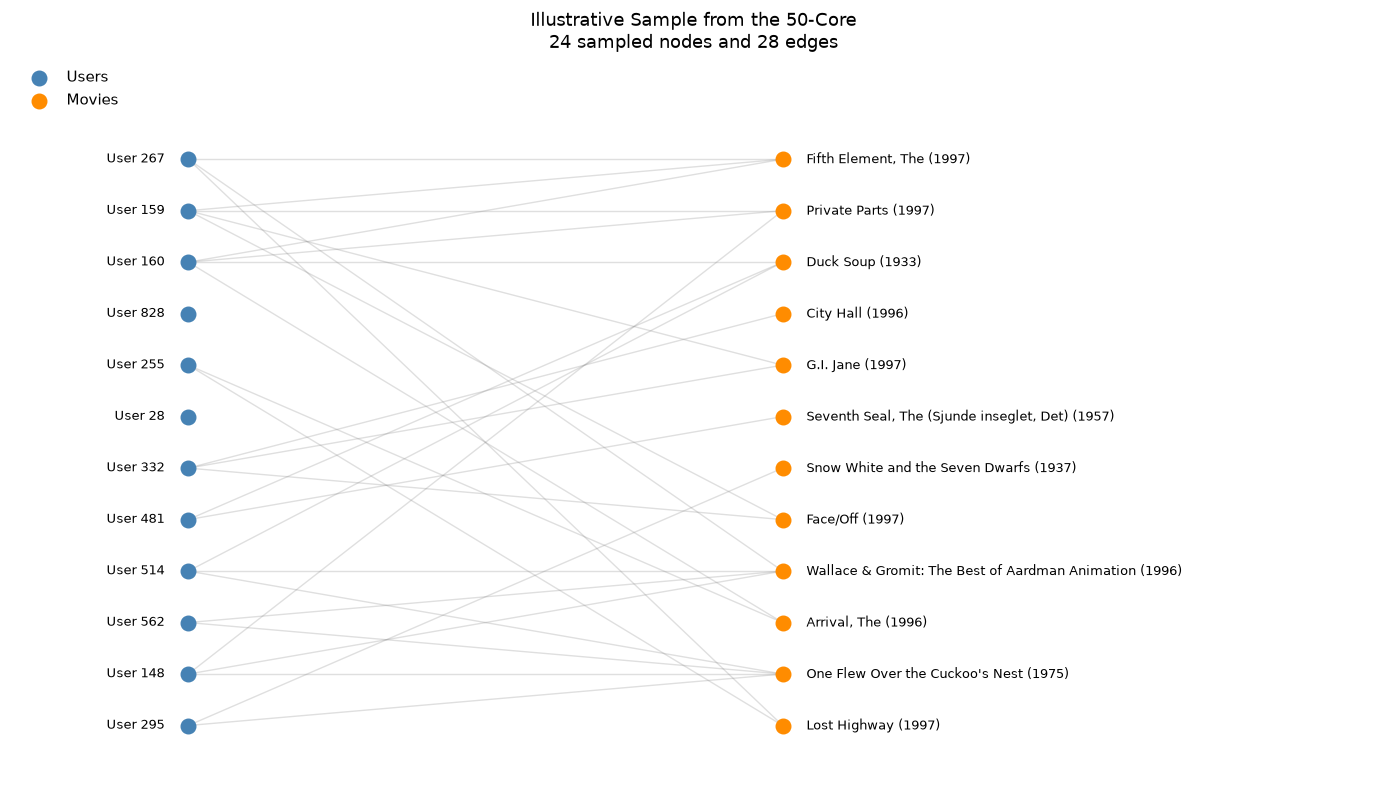

In [17]:
import random

rng = random.Random(42)

sample_users = rng.sample(sorted(reduced_users), 12)
sample_movies = rng.sample(sorted(reduced_movies), 12)

visual_graph = B_reduced.subgraph(
    sample_users + sample_movies
).copy()

positions = {
    node: (0, i)
    for i, node in enumerate(sample_users)
}
positions.update({
    node: (1, i)
    for i, node in enumerate(sample_movies)
})

fig, ax = plt.subplots(figsize=(14, 8))

nx.draw_networkx_edges(
    visual_graph,
    positions,
    ax=ax,
    alpha=0.25,
    edge_color="gray"
)

nx.draw_networkx_nodes(
    visual_graph,
    positions,
    nodelist=sample_users,
    node_color="steelblue",
    node_size=110,
    label="Users",
    ax=ax
)

nx.draw_networkx_nodes(
    visual_graph,
    positions,
    nodelist=sample_movies,
    node_color="darkorange",
    node_size=110,
    label="Movies",
    ax=ax
)

for node in sample_users:
    x, y = positions[node]
    ax.text(
        x - 0.04, y,
        f"User {B.nodes[node]['user_id']}",
        ha="right", va="center", fontsize=9
    )

for node in sample_movies:
    x, y = positions[node]
    ax.text(
        x + 0.04, y,
        B.nodes[node]["title"],
        ha="left", va="center", fontsize=9
    )

ax.set_title(
    "Illustrative Sample from the 50-Core\n"
    f"24 sampled nodes and {visual_graph.number_of_edges()} edges"
)
ax.set_xlim(-0.3, 2.0)
ax.set_ylim(-1, 13)
ax.legend(loc="upper left", frameon=False)
ax.axis("off")

plt.tight_layout()
plt.show()

## Limitations

The MovieLens users and their recorded ratings are not representative of all movie audiences. An absent edge indicates that no rating was recorded in this dataset; it does not establish that the user did not watch or disliked the movie.

The 50-core threshold is an exploratory choice rather than a statistically optimal cutoff. Comparing several thresholds shows that the amount of retained information depends on this choice.

K-core reduction favors users and movies with many connections to other retained nodes. Consequently, less active users and less frequently rated movies are underrepresented. Increased density is an expected result of this filtering.

Rating averages in the reduced network reflect a selected group of users. Differences from the original averages should not be interpreted as changes in opinion over time.

## Conclusion

This project constructed a bipartite network containing 943 users, 1,682 movies, and 100,000 rating relationships. All edges connected users to movies, satisfying the requirement for ties between distinct groups.

A 50-core reduction produced a connected network of 513 users, 560 movies, and 69,222 edges. It removed approximately 59.1% of nodes while retaining 69.2% of rating relationships.

For users, the analysis identified participants with extensive connections within the retained catalog. User 13 had the highest reduced degree, although user 655 had rated more movies overall. This demonstrates that a user's position depends on which movies remain in the network.

For movies, Star Wars received the most ratings within the reduced network. Comparing rating counts with average scores demonstrated that frequent rating activity does not necessarily imply equally favorable evaluations.

The reduction also changed genre representation. Action, thriller, adventure, and science fiction increased their shares, while drama and documentaries decreased. These findings show how network reduction highlights a connected subset of participation while excluding some of the original catalog's diversity.

## References

- GroupLens Research. *MovieLens 100K Dataset*.  
  https://grouplens.org/datasets/movielens/100k/

- GitHub-hosted dataset copy used for direct loading. *SPARK: MovieLens 100K files*.  
  https://github.com/jsnowacki/SPARK/tree/master/data/ml-100k

- NetworkX. *K-core documentation*.  
  https://networkx.org/documentation/stable/reference/algorithms/generated/networkx.algorithms.core.k_core.html

- NetworkX. *Bipartite algorithms*.  
  https://networkx.org/documentation/stable/reference/algorithms/bipartite.html